"""
Toy DPO vs. offline GRPO (O-GRPO, as in HumorGen Sec. 4.2-4.3 / App. H).

Simplest possible setting:
  - 1 prompt x, G = 6 fixed candidate jokes y_0..y_5 (think: one per persona)
  - "Policy" = tabular softmax over the 6 candidates: pi_theta(y_k|x) = softmax(theta)_k
  - Each candidate has a pre-computed Elo score (from the offline judge)
For a softmax policy:  grad_theta log pi(y_k) = e_k - pi,  so all gradients are analytic.
"""

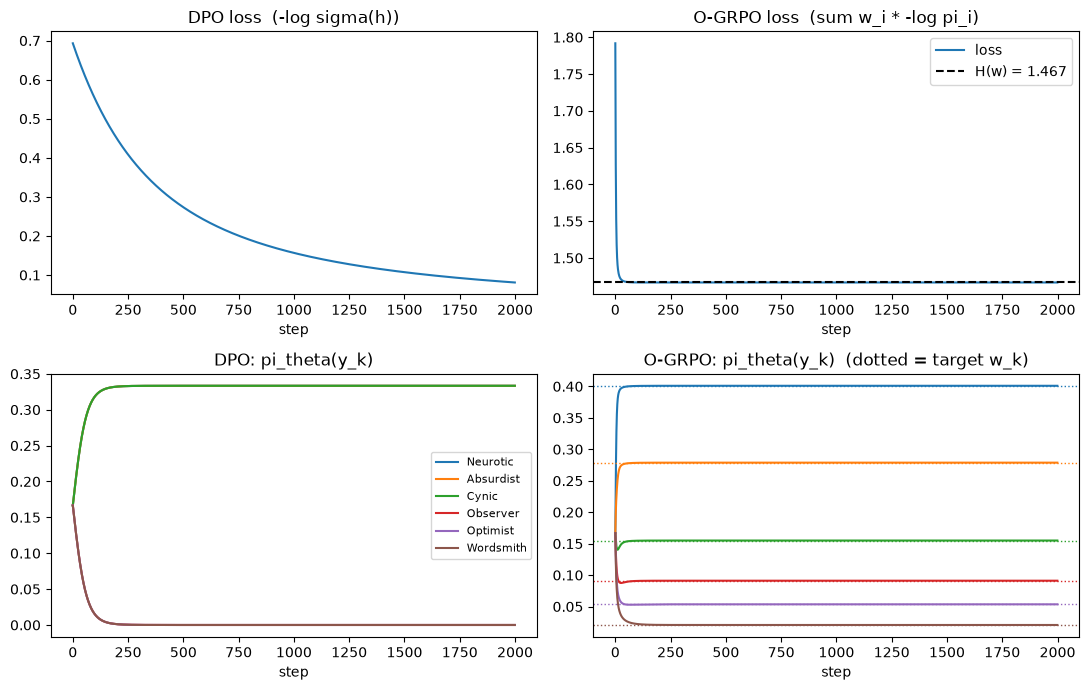

In [2]:

import numpy as np
import matplotlib.pyplot as plt


G = 6
elo = np.array([1053.0, 1040.0, 1019.0, 1000.0, 981.0, 947.0])  # y_0 best ... y_5 worst
names = ["Neurotic", "Absurdist", "Cynic", "Observer", "Optimist", "Wordsmith"]

def softmax(z):
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

theta_ref = np.zeros(G)                 # reference policy (stand-in for the SFT model): uniform
logp_ref = np.log(softmax(theta_ref))

# ---------------- DPO (Eq. 1) ----------------
# L = -E log sigma( beta*[ (log pi(yw)-log pi_ref(yw)) - (log pi(yl)-log pi_ref(yl)) ] )
# dL/dtheta = -(1 - sigma(h)) * beta * (e_w - e_l)      (the "- pi" terms cancel)
def train_dpo(pairs, beta=0.1, lr=1.0, steps=2000):
    theta = theta_ref.copy()
    for t in range(steps):
        logp = np.log(softmax(theta))
        grad, loss = np.zeros(G), 0.0
        for w, l in pairs:
            h = beta * ((logp[w] - logp_ref[w]) - (logp[l] - logp_ref[l]))
            s = 1.0 / (1.0 + np.exp(-h))
            loss += -np.log(s)
            g = np.zeros(G)
            g[w] += 1.0; g[l] -= 1.0
            grad += -(1.0 - s) * beta * g
        theta -= lr * grad / len(pairs)
        if t % 500 == 0:
            print(f"  DPO step {t:4d}  loss {loss/len(pairs):.4f}")
    return softmax(theta)

# ---------------- O-GRPO (Eqs. 3-5) ----------------
# A_i = (r_i - mean) / (std + eps);  w_i = softmax(A/T);  L = sum_i w_i * (-log pi(y_i))
# dL/dtheta = pi - w   ->  fixed point: pi = w
def train_ogrpo(T=1.0, lr=1.0, steps=2000):
    A = (elo - elo.mean()) / (elo.std() + 1e-6)
    w = softmax(A / T)
    theta = theta_ref.copy()
    for t in range(steps):
        pi = softmax(theta)
        loss = -(w * np.log(pi)).sum()
        theta -= lr * (pi - w)
        if t % 500 == 0:
            print(f"  O-GRPO step {t:4d}  loss {loss:.4f}")
    return softmax(theta), A, w

# ---------------- Visualization ----------------
# Re-runs both update rules while recording loss and pi_theta at every step.
if __name__ == "__main__":
    pairs = [(0, 5), (1, 4), (2, 3)]                 # (chosen, rejected): top-3 vs bottom-3
    A = (elo - elo.mean()) / (elo.std() + 1e-6)      # group z-score advantages, Eq. 3
    w = softmax(A / 1.0)                             # O-GRPO target weights, Eq. 4 (T = 1)

    def history_dpo(pairs, beta=0.1, lr=1.0, steps=2000):
        theta, L, P = theta_ref.copy(), [], []
        for _ in range(steps):
            logp = np.log(softmax(theta))
            grad, loss = np.zeros(G), 0.0
            for wi, li in pairs:
                h = beta * ((logp[wi] - logp_ref[wi]) - (logp[li] - logp_ref[li]))
                s = 1.0 / (1.0 + np.exp(-h))
                loss += -np.log(s)
                grad[wi] -= (1 - s) * beta; grad[li] += (1 - s) * beta
            L.append(loss / len(pairs)); P.append(np.exp(logp))
            theta -= lr * grad / len(pairs)
        return np.array(L), np.array(P)

    def history_ogrpo(w, lr=1.0, steps=2000):
        theta, L, P = theta_ref.copy(), [], []
        for _ in range(steps):
            pi = softmax(theta)
            L.append(-(w * np.log(pi)).sum()); P.append(pi)
            theta -= lr * (pi - w)
        return np.array(L), np.array(P)

    L_dpo, P_dpo = history_dpo(pairs)
    L_grpo, P_grpo = history_ogrpo(w)
    H_w = -(w * np.log(w)).sum()          # min of O-GRPO loss = entropy of w

    fig, ax = plt.subplots(2, 2, figsize=(11, 7))
    ax[0, 0].plot(L_dpo); ax[0, 0].set_title("DPO loss  (-log sigma(h))")
    ax[0, 1].plot(L_grpo, label="loss")
    ax[0, 1].axhline(H_w, ls="--", c="k", label=f"H(w) = {H_w:.3f}")
    ax[0, 1].set_title("O-GRPO loss  (sum w_i * -log pi_i)"); ax[0, 1].legend()
    for k in range(G):
        c = f"C{k}"
        ax[1, 0].plot(P_dpo[:, k], c=c, label=names[k])
        ax[1, 1].plot(P_grpo[:, k], c=c, label=names[k])
        ax[1, 1].axhline(w[k], c=c, ls=":", lw=1)
    ax[1, 0].set_title("DPO: pi_theta(y_k)"); ax[1, 0].legend(fontsize=8)
    ax[1, 1].set_title("O-GRPO: pi_theta(y_k)  (dotted = target w_k)")
    for a in ax.flat: a.set_xlabel("step")
    plt.tight_layout()
